# Analyse métier - Étoile Finance et paiements

**Table Druid :** fact_payment  
**Grain :** Une ligne par commande et type de paiement dans le Parquet préparé (les séquences ne sont pas conservées par le traitement courant)

Ce notebook exécute cinquante visuels depuis la table Druid dénormalisée indiquée ci-dessus. La première cellule détecte une connexion accessible depuis le noyau Python : `http://127.0.0.1:25019/druid/v2/sql` sur l’hôte ou `http://druid-router:8888/druid/v2/sql` dans Docker. Pour imposer une URL, définir `DRUID_SQL_URL_OVERRIDE` ou la variable d’environnement `DRUID_SQL_URL`.

**Limite du modèle :** Le script du projet indique que payments.parquet est pivoté par commande et reconstruit un grain commande x type de paiement. Ne pas présenter cette étoile comme un détail de séquence de paiement. Les échéances sont conservées au niveau disponible dans ce Parquet.

**Source du modèle :** [20_build_ebrasil_warehouse.py](https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py), blob GitHub `8b553b3970eb8f3f5804ac0072569cfade518c57`. Le script produit les six tables dénormalisées ; `docker/ebrasil-druid/ingest.py` les ingère sous les mêmes noms, sans rollup. Au démarrage, le notebook contrôle les six tables et les colonnes utilisées par ses graphiques via `INFORMATION_SCHEMA.COLUMNS`, ainsi que la présence de lignes dans sa table. Aucune donnée de démonstration ni dimension séparée n’est utilisée. La compatibilité du schéma est contrôlée ; la provenance des lignes dépend de l’initialisation eBrasil du dépôt.


In [1]:
import os
import socket
import warnings
from pathlib import Path
from urllib.parse import urlsplit, urlunsplit
import requests
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# None : sélection automatique depuis le noyau Python, indépendamment du navigateur.
# Pour imposer une adresse, renseigner ceci ou la variable d'environnement DRUID_SQL_URL.
DRUID_SQL_URL_OVERRIDE = None
HOST_SQL_URL = "http://127.0.0.1:25019/druid/v2/sql"
DOCKER_SQL_URL = "http://druid-router:8888/druid/v2/sql"
TABLE = "fact_payment"
MODEL_TABLES = ["fact_logistics","fact_order","fact_order_item","fact_payment","fact_review","mart_customer_rfm"]
REQUIRED_COLUMNS = ["customer_city","customer_state","customer_unique_id","customer_zip_code","installments","order_id","payment_type","payment_value","purchase_date_calendar_date","purchase_date_quarter","purchase_date_weekday","purchase_date_year","purchase_time_day_part","purchase_time_hour","transaction_count"]
MODEL_SOURCE = "https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py"
MODEL_SOURCE_BLOB_SHA = "8b553b3970eb8f3f5804ac0072569cfade518c57"

def normalize_sql_url(value):
    parsed = urlsplit(value.strip())
    if parsed.scheme not in ("http", "https") or not parsed.hostname:
        raise ValueError("DRUID_SQL_URL doit être une URL HTTP complète, sans syntaxe Markdown.")
    if parsed.username or parsed.password or parsed.query or parsed.fragment:
        raise ValueError("Ne pas inclure d'identifiants, de paramètres ou de fragment dans DRUID_SQL_URL.")
    netloc = parsed.netloc
    if parsed.hostname == "druid-router" and parsed.port == 25019:
        warnings.warn("Port corrigé : druid-router utilise 8888 ; 25019 est le port de l'hôte.")
        netloc = "druid-router:8888"
    if parsed.hostname in ("localhost", "127.0.0.1") and parsed.port == 8888:
        warnings.warn("Port hôte corrigé selon le dépôt : 127.0.0.1:25019.")
        netloc = "127.0.0.1:25019"
    path = parsed.path.rstrip("/") or "/druid/v2/sql"
    if path != "/druid/v2/sql":
        raise ValueError("Le point d'accès attendu est /druid/v2/sql.")
    return urlunsplit((parsed.scheme, netloc, path, "", ""))

def select_druid_url():
    explicit = DRUID_SQL_URL_OVERRIDE or os.getenv("DRUID_SQL_URL", "").strip()
    try:
        socket.getaddrinfo("druid-router", 8888)
        docker_dns = True
    except OSError:
        docker_dns = False
    in_docker = Path("/.dockerenv").exists() or docker_dns
    candidates = [DOCKER_SQL_URL, HOST_SQL_URL] if in_docker else [HOST_SQL_URL, DOCKER_SQL_URL]
    if explicit:
        candidates = [normalize_sql_url(explicit)]
    errors = []
    for url in candidates:
        try:
            response = requests.post(url, json={"query": "SELECT 1 AS connexion_ok", "resultFormat": "object"}, timeout=(3, 8))
            response.raise_for_status()
            result = response.json()
            if not isinstance(result, list) or not result or result[0].get("connexion_ok") != 1:
                raise ValueError("Ce service ne répond pas comme Druid SQL.")
            return url
        except (requests.RequestException, ValueError) as exc:
            errors.append(f"{url} : {exc}")
    raise ConnectionError(
        "Connexion Druid impossible depuis ce noyau Python.\nWindows : " + HOST_SQL_URL +
        "\nDocker du dépôt : " + DOCKER_SQL_URL +
        "\nVérifier druid-router et le réseau Docker. Corriger ou supprimer la variable DRUID_SQL_URL si elle est définie.\n" +
        "\n".join(errors)
    )

DRUID_SQL_URL = select_druid_url()

def druid_sql(sql):
    try:
        response = requests.post(DRUID_SQL_URL,
            json={"query": sql, "resultFormat": "object",
                  "context": {"sqlTimeZone": "UTC", "useApproximateCountDistinct": False}}, timeout=(5, 120))
    except requests.RequestException as exc:
        raise ConnectionError(f"Druid inaccessible à {DRUID_SQL_URL}. Relancer la cellule de connexion.") from exc
    if not response.ok:
        raise RuntimeError(f"Druid SQL HTTP {response.status_code}\nSQL : {sql}\n{response.text[:3000]}")
    data = response.json()
    if not isinstance(data, list):
        raise ValueError("Druid doit renvoyer une liste d'objets JSON.")
    return pd.DataFrame(data)

# Toutes les données analysées proviennent des tables dénormalisées exposées par Druid.
model_names = ", ".join("'" + name + "'" for name in MODEL_TABLES)
schema = druid_sql(
    'SELECT TABLE_NAME AS "table_name", COLUMN_NAME AS "column_name", DATA_TYPE AS "data_type" '
    "FROM INFORMATION_SCHEMA.COLUMNS WHERE TABLE_SCHEMA = 'druid' AND TABLE_NAME IN (" + model_names + ")"
)
if schema.empty:
    raise RuntimeError("Aucune étoile eBrasil dans Druid : exécuter l'initialisation du dépôt.")
missing_tables = set(MODEL_TABLES) - set(schema["table_name"])
if missing_tables:
    raise RuntimeError("Tables Druid manquantes : " + ", ".join(sorted(missing_tables)))
present_columns = set(schema.loc[schema["table_name"] == TABLE, "column_name"])
missing_columns = set(REQUIRED_COLUMNS) - present_columns
if missing_columns:
    raise RuntimeError(f"Schéma incompatible pour {TABLE}. Colonnes dénormalisées manquantes : " +
        ", ".join(sorted(missing_columns)) + ". Reconstruire avec 20_build_ebrasil_warehouse.py puis réingérer dans Druid.")
row_count = int(druid_sql(f'SELECT COUNT(*) AS lignes FROM "{TABLE}"').iloc[0]["lignes"])
if row_count == 0:
    raise RuntimeError(f"La table Druid {TABLE} est vide.")
print("Druid SQL :", DRUID_SQL_URL)
print(f"Table : {TABLE} | {row_count:,} lignes | {len(REQUIRED_COLUMNS)} colonnes contrôlées")
print("Source du modèle :", MODEL_SOURCE)
display(schema.loc[schema["table_name"] == TABLE].reset_index(drop=True))


Druid SQL : http://127.0.0.1:25019/druid/v2/sql
Table : fact_payment | 103,877 lignes | 15 colonnes contrôlées
Source du modèle : https://github.com/rbizoi/FormationBigDataBI/blob/master/spark/jobs/20_build_ebrasil_warehouse.py


,table_name,column_name,data_type
0,fact_payment,__time,TIMESTAMP
1,fact_payment,order_id,VARCHAR
2,fact_payment,payment_type,VARCHAR
3,fact_payment,customer_unique_id,VARCHAR
4,fact_payment,purchase_date_key,VARCHAR
5,fact_payment,purchase_time_key,VARCHAR
6,fact_payment,customer_customer_id,VARCHAR
7,fact_payment,customer_zip_code,VARCHAR
8,fact_payment,customer_city,VARCHAR
9,fact_payment,customer_state,VARCHAR


In [2]:
def build_chart_sql(spec):
    """Construit une requête Druid avec des alias délimités, y compris VALUE."""
    dim, metric, kind = spec["dim"], spec["metric"], spec["kind"]
    fields = [dim["sql"] + ' AS "x"']
    if dim.get("series"):
        fields.append(dim["series"] + ' AS "series"')
    fields.append(metric["sql"] + ' AS "value"')
    group_by = "1, 2" if dim.get("series") else "1"
    order_by = '"x"' if kind == "line" else '"value" DESC'
    table_name = TABLE.replace('"', '""')
    return ('SELECT ' + ', '.join(fields) + ' FROM "' + table_name +
            '" GROUP BY ' + group_by + ' ORDER BY ' + order_by + ' LIMIT 40')

def run_chart(spec):
    dim,metric,kind=spec["dim"],spec["metric"],spec["kind"]
    if dim["type"]=="client":
        xcol=dim["sql"].replace('"',""); frame=rfm.copy(); scol=(dim.get("series") or "").replace('"',"")
        if xcol not in frame.columns: raise KeyError("Dimension RFM manquante: "+xcol)
        by=[xcol]+([scol] if scol else [])
        if metric["pandas"]=="customer_unique_id": grouped=frame.groupby(by,dropna=False)["customer_unique_id"].nunique().reset_index(name="value")
        else:
            agg="sum" if metric["pandas"]=="monetary" else "mean"
            grouped=frame.groupby(by,dropna=False)[metric["pandas"]].agg(agg).reset_index(name="value")
        if scol: grouped=grouped.pivot(index=xcol,columns=scol,values="value").fillna(0).head(25)
        else: grouped=grouped.sort_values("value",ascending=False).head(25).set_index(xcol)["value"]
    else:
        sql = build_chart_sql(spec)
        result=druid_sql(sql)
        if result.empty: print("Aucune donnée pour",spec["title"]); return
        if dim.get("series"): grouped=result.pivot_table(index="x",columns="series",values="value",aggfunc="sum",fill_value=0).head(25)
        else:
            result=result.sort_values("x" if kind=="line" else "value",ascending=(kind=="line")); grouped=result.set_index("x")["value"].head(40)
    fig,ax=plt.subplots(figsize=(10,5))
    if isinstance(grouped,pd.DataFrame):
        if kind=="heatmap":
            img=ax.imshow(grouped.values,aspect="auto",cmap="YlGnBu")
            ax.set_yticks(range(len(grouped.index))); ax.set_yticklabels([str(v) for v in grouped.index])
            ax.set_xticks(range(len(grouped.columns))); ax.set_xticklabels([str(v) for v in grouped.columns],rotation=45,ha="right")
            fig.colorbar(img,ax=ax,label=metric["label"])
        else: grouped.plot(kind="bar",stacked=True,ax=ax,colormap="tab20"); ax.legend(title="Série",bbox_to_anchor=(1.02,1),loc="upper left")
    elif kind=="line": grouped.plot(kind="line",marker="o",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    elif kind=="scatter": ax.scatter(pd.to_numeric(pd.Series(grouped.index),errors="coerce"),grouped.values,color="#148A8A",alpha=.75)
    else: grouped.plot(kind="bar",ax=ax,color="#148A8A"); ax.tick_params(axis="x",rotation=45)
    ax.set_title(spec["title"]); ax.set_xlabel(dim["label"]); ax.set_ylabel(metric["label"])
    fig.tight_layout(); plt.show(); plt.close(fig)


## 1. Mix des moyens de paiement

Quantifier les montants et commandes associés à chaque type de paiement et observer leur évolution temporelle.

**Drill-down :** Type > date d’achat; type > état/ville client; date année > trimestre > mois > jour.

Visuel 1 - Mix des moyens de paiement - Type paiement


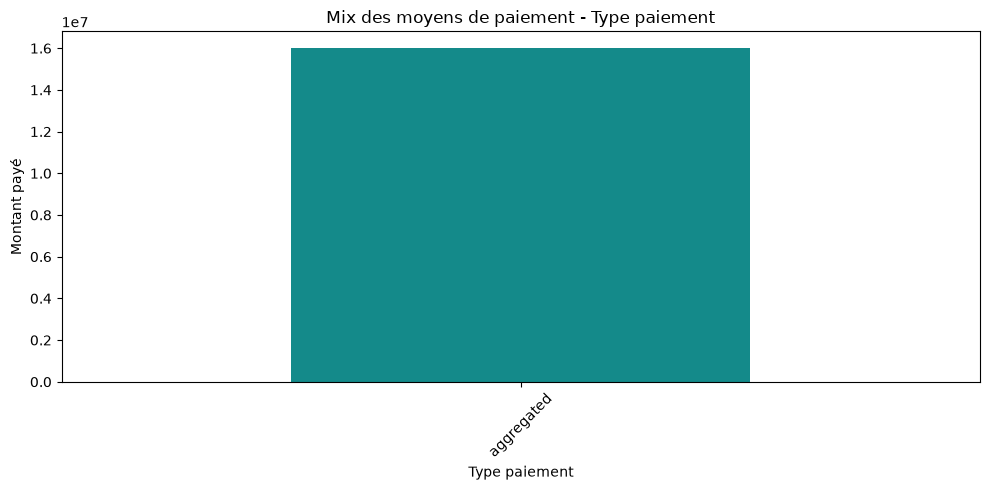

Visuel 2 - Mix des moyens de paiement - Mois achat


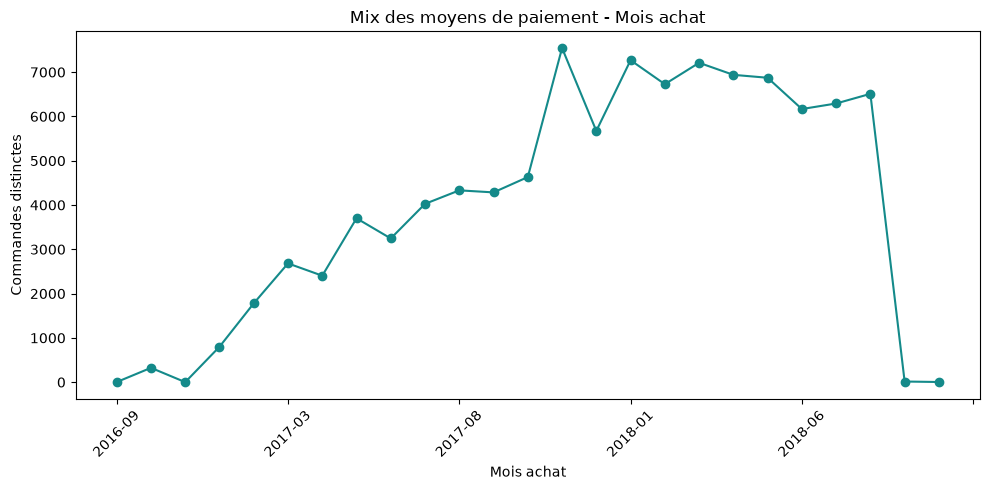

Visuel 3 - Mix des moyens de paiement - Année achat


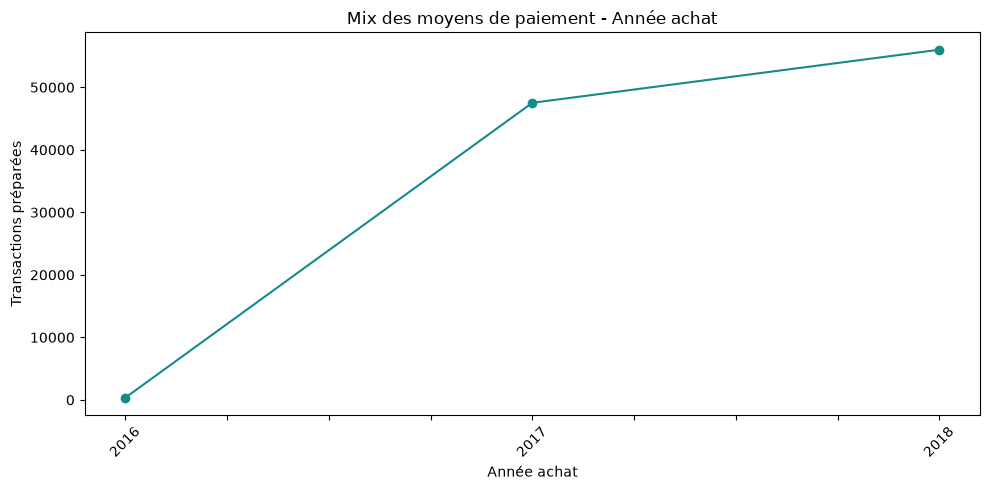

Visuel 4 - Mix des moyens de paiement - Trimestre achat


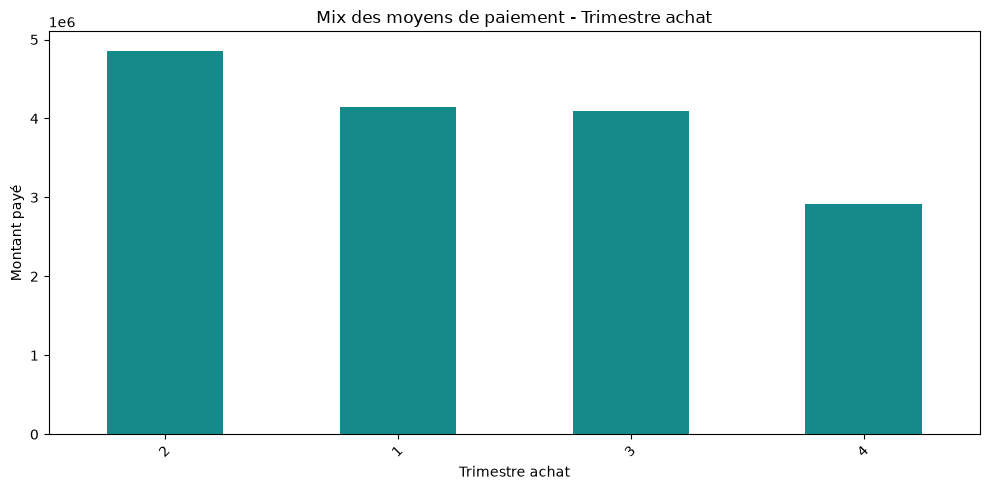

Visuel 5 - Mix des moyens de paiement - Jour semaine


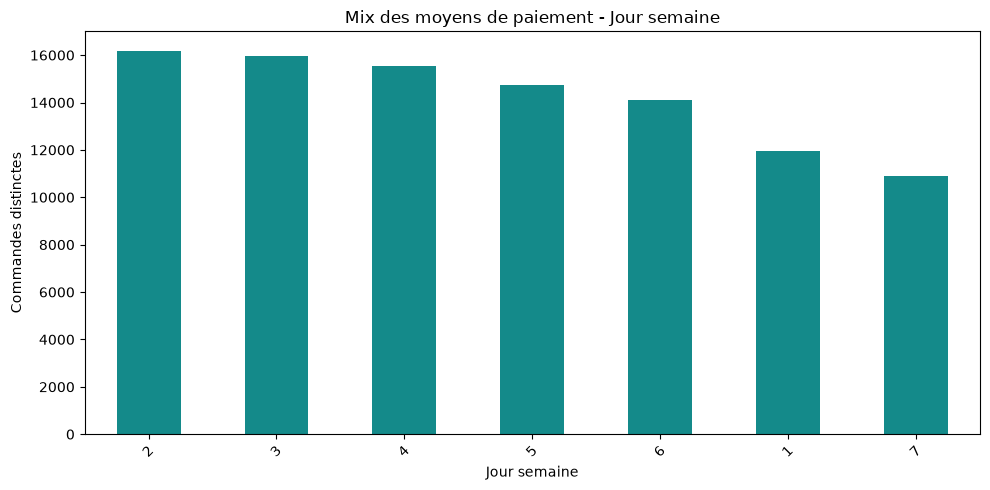

Visuel 6 - Mix des moyens de paiement - Partie du jour


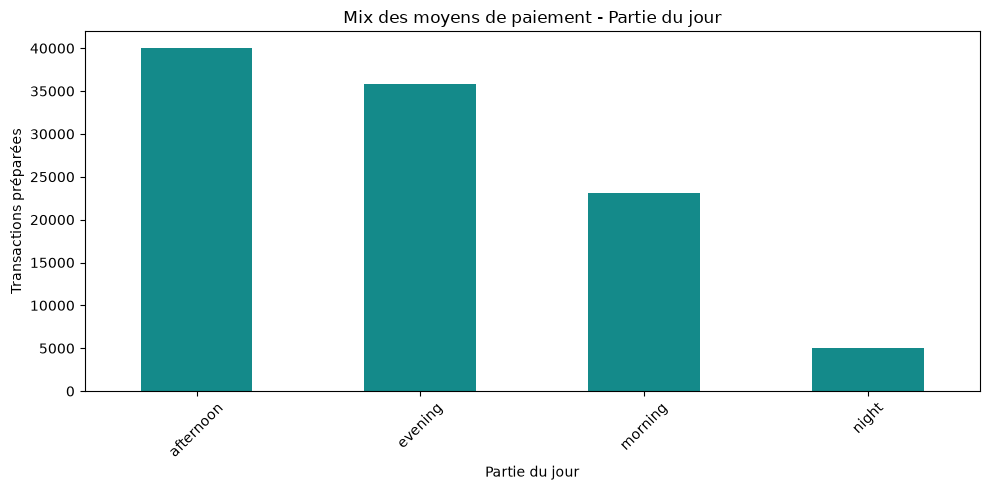

Visuel 7 - Mix des moyens de paiement - État client


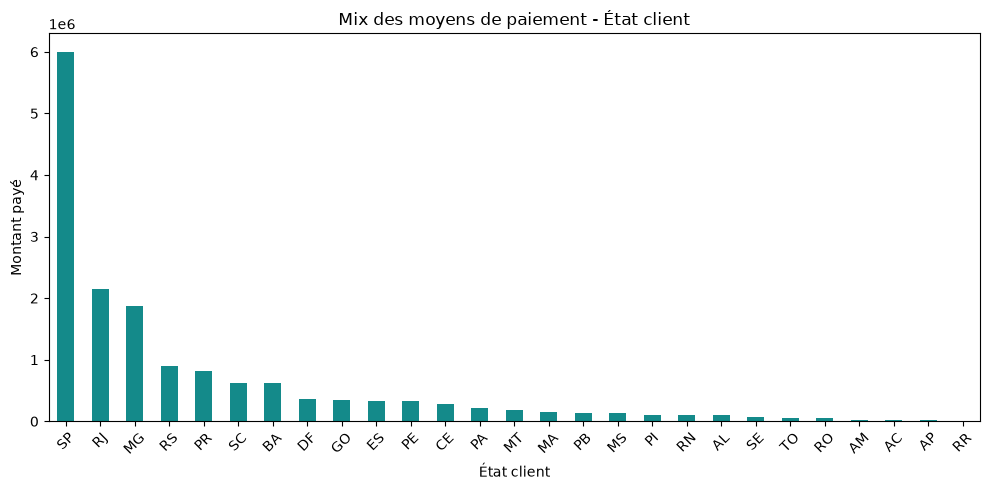

Visuel 8 - Mix des moyens de paiement - Type x mois


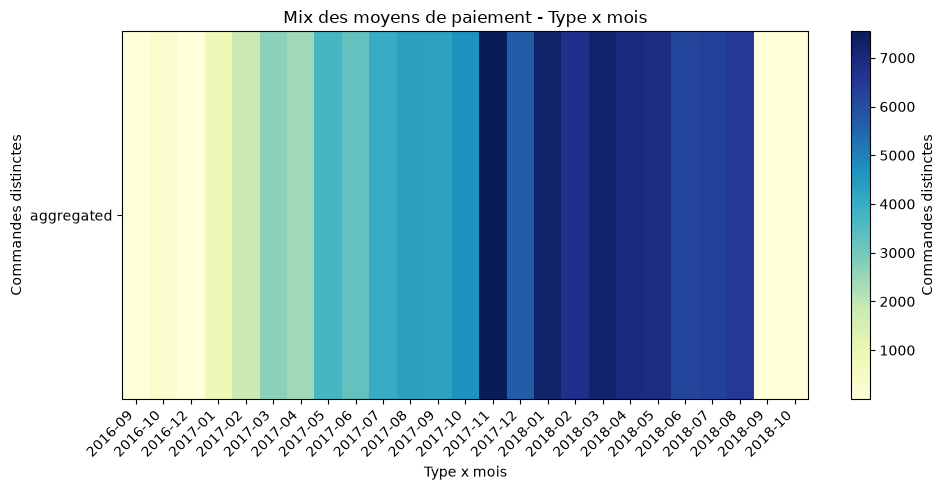

Visuel 9 - Mix des moyens de paiement - Type x état


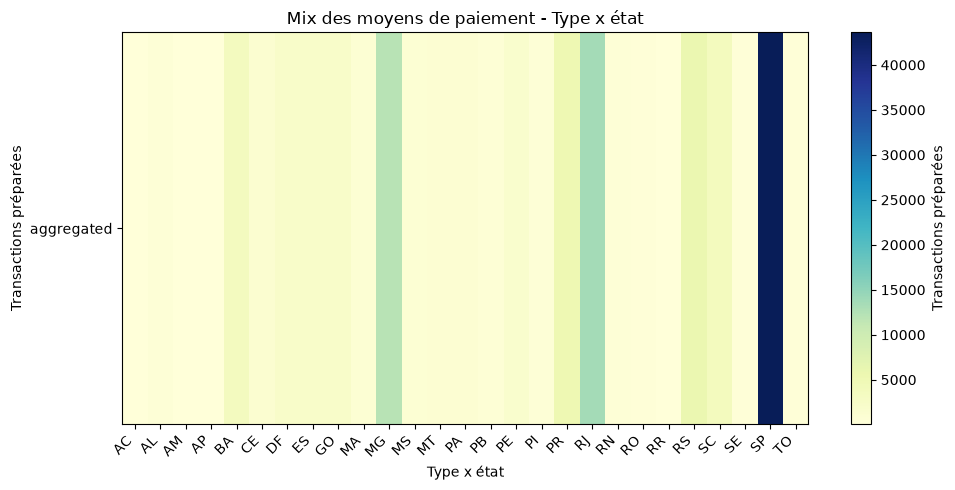

Visuel 10 - Mix des moyens de paiement - Ville client


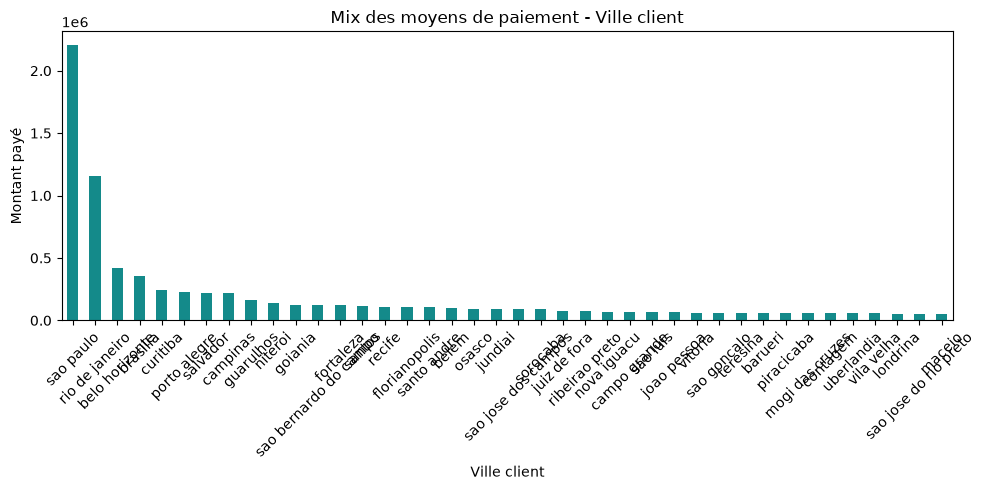

In [3]:
CHARTS=[
  {
    "n": 1,
    "title": "Mix des moyens de paiement - Type paiement",
    "dim": {
      "label": "Type paiement",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Mix des moyens de paiement - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Mix des moyens de paiement - Année achat",
    "dim": {
      "label": "Année achat",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Transactions préparées",
      "sql": "SUM(\"transaction_count\")",
      "pandas": "transaction_count"
    },
    "kind": "line"
  },
  {
    "n": 4,
    "title": "Mix des moyens de paiement - Trimestre achat",
    "dim": {
      "label": "Trimestre achat",
      "sql": "\"purchase_date_quarter\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Mix des moyens de paiement - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Mix des moyens de paiement - Partie du jour",
    "dim": {
      "label": "Partie du jour",
      "sql": "\"purchase_time_day_part\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Transactions préparées",
      "sql": "SUM(\"transaction_count\")",
      "pandas": "transaction_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Mix des moyens de paiement - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Mix des moyens de paiement - Type x mois",
    "dim": {
      "label": "Type x mois",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Mix des moyens de paiement - Type x état",
    "dim": {
      "label": "Type x état",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": "\"customer_state\""
    },
    "metric": {
      "label": "Transactions préparées",
      "sql": "SUM(\"transaction_count\")",
      "pandas": "transaction_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Mix des moyens de paiement - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 2. Échéanciers et recours au paiement fractionné

Étudier le nombre d’échéances, les montants et les moyens de paiement associés aux modalités de fractionnement.

**Drill-down :** Nombre d’échéances > type > montant; type > client et calendrier; toujours comparer volumes et montants.

Visuel 1 - Échéanciers et recours au paiement fractionné - Échéances


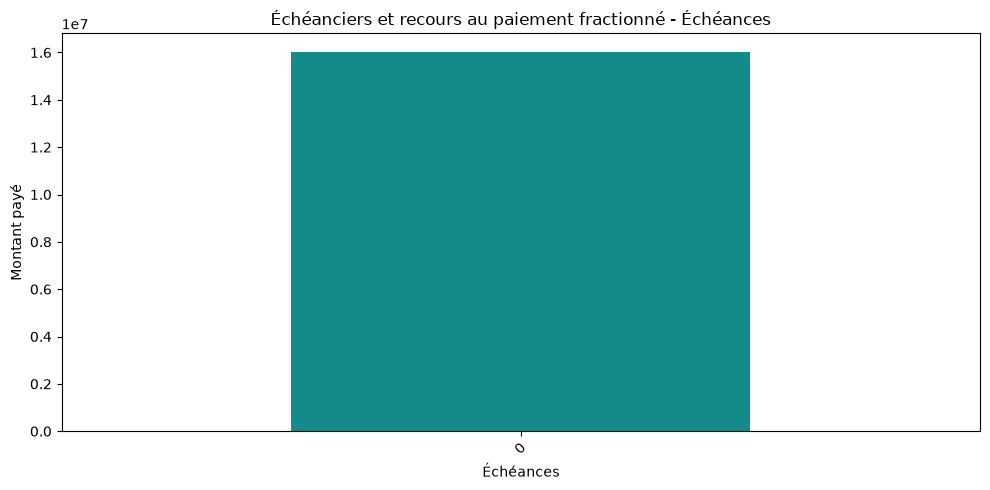

Visuel 2 - Échéanciers et recours au paiement fractionné - Type paiement


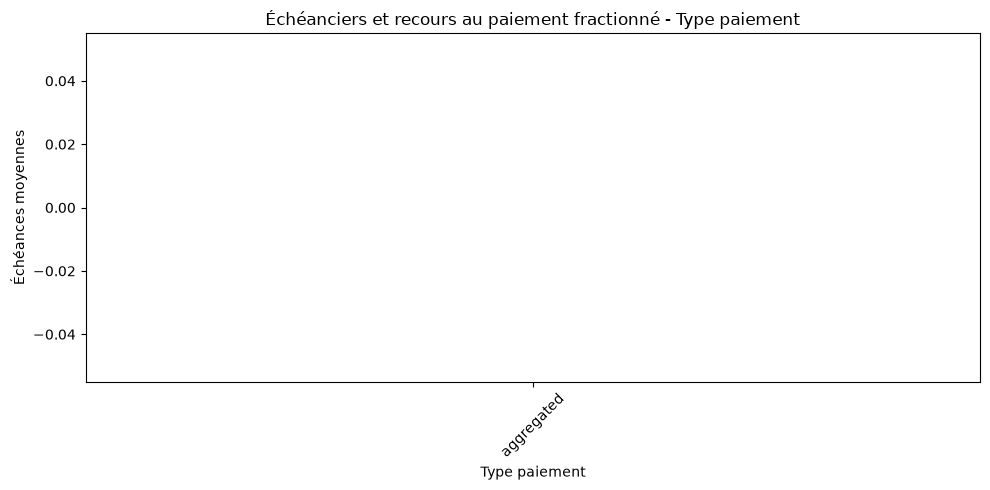

Visuel 3 - Échéanciers et recours au paiement fractionné - Montant par tranche 50


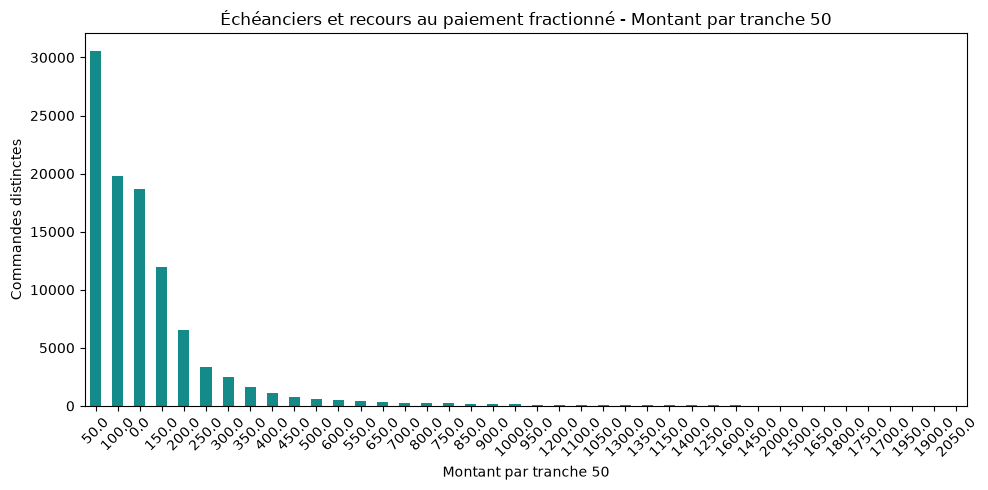

Visuel 4 - Échéanciers et recours au paiement fractionné - Mois achat


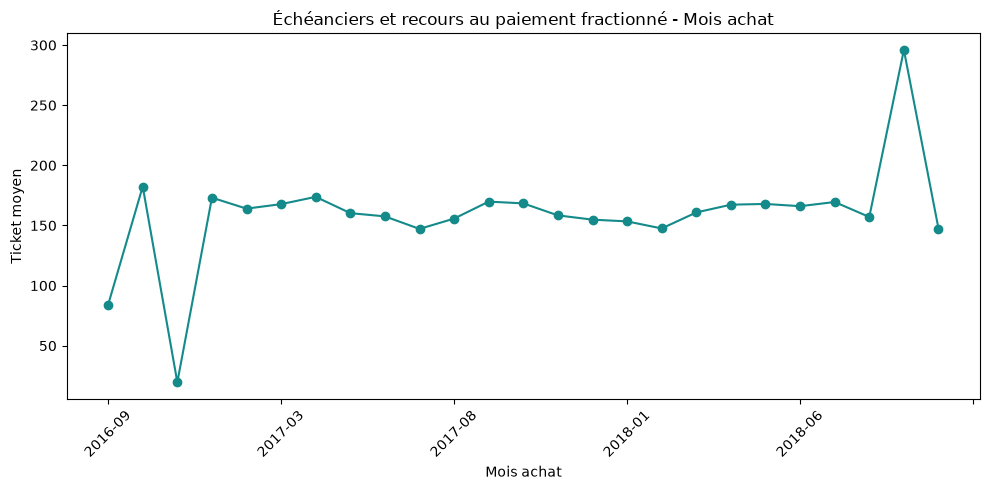

Visuel 5 - Échéanciers et recours au paiement fractionné - État client


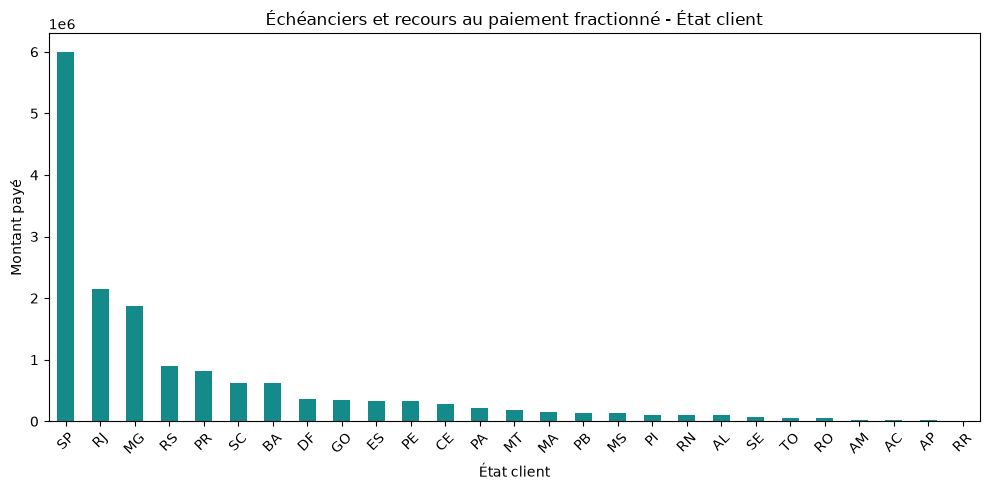

Visuel 6 - Échéanciers et recours au paiement fractionné - Jour semaine


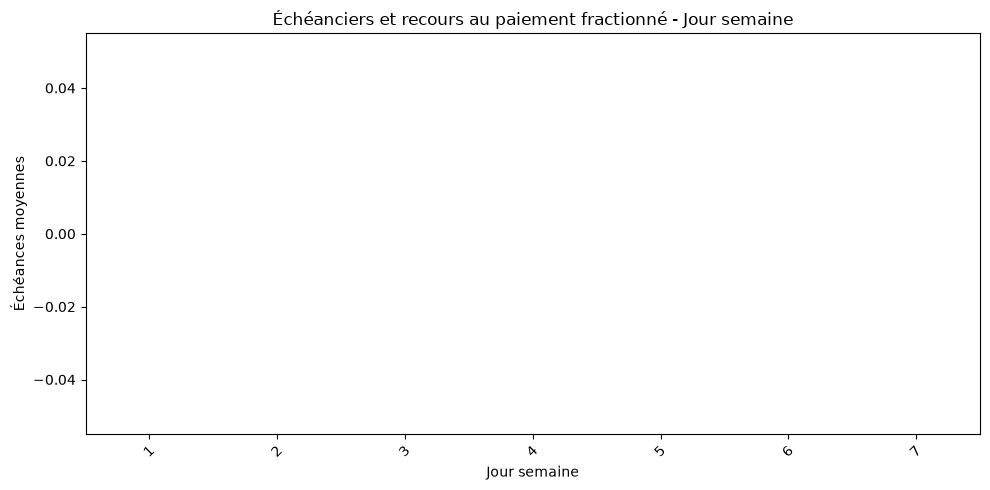

Visuel 7 - Échéanciers et recours au paiement fractionné - Heure


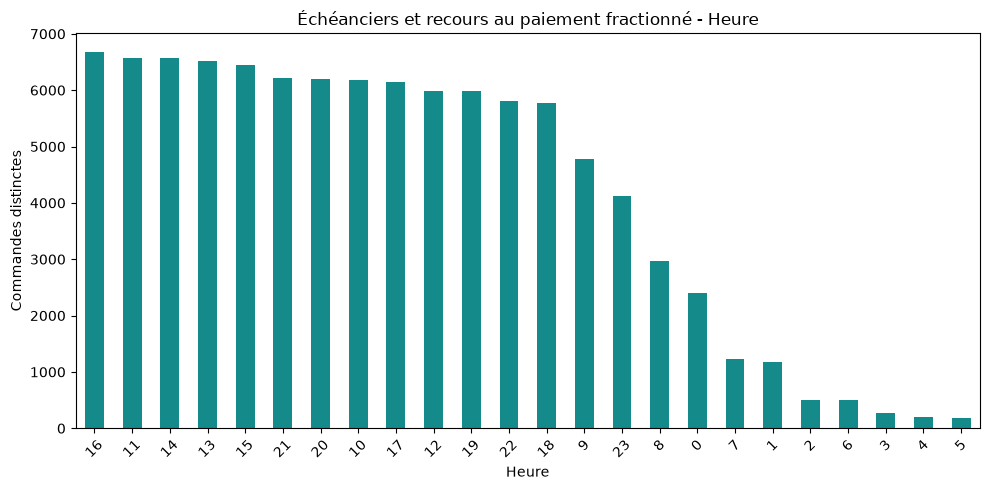

Visuel 8 - Échéanciers et recours au paiement fractionné - Échéances x type


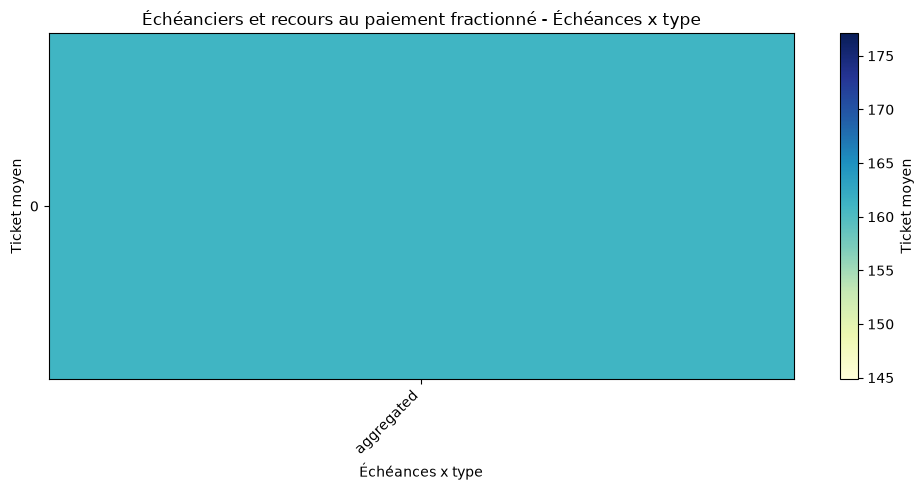

Visuel 9 - Échéanciers et recours au paiement fractionné - Type x mois


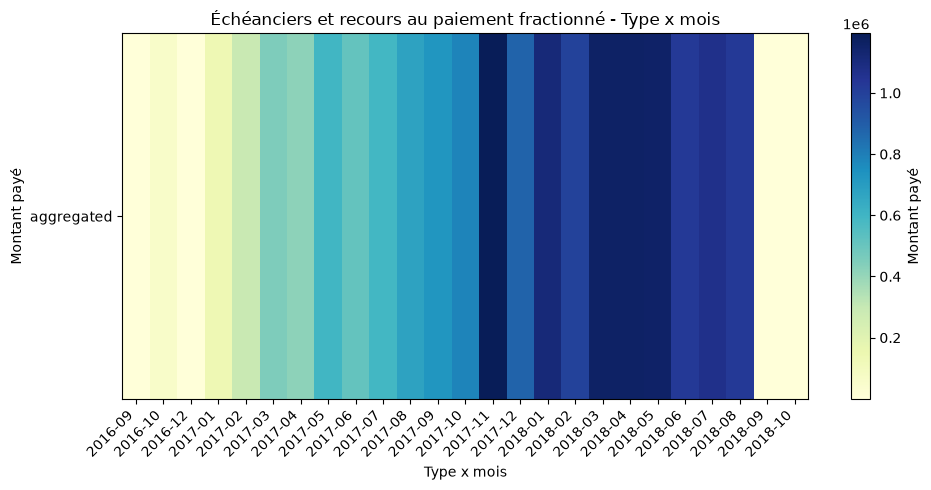

Visuel 10 - Échéanciers et recours au paiement fractionné - Échéances x montant tranche


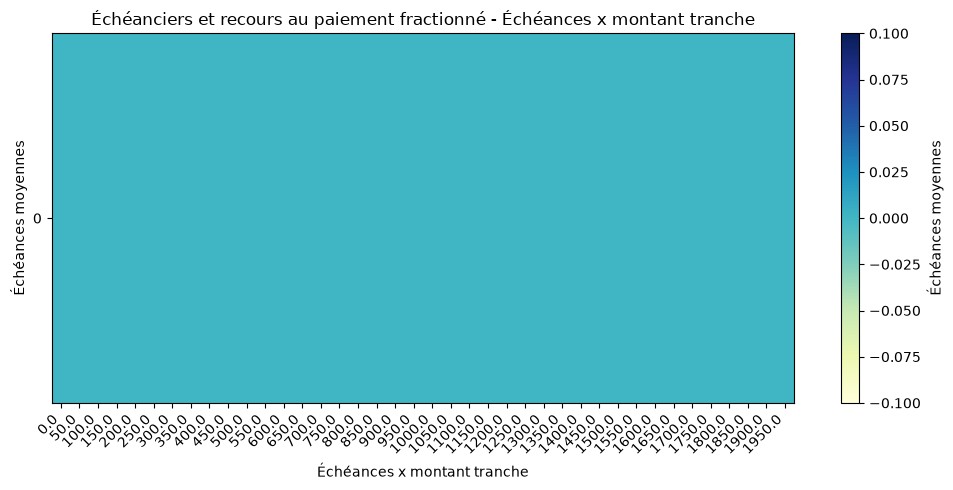

In [4]:
CHARTS=[
  {
    "n": 1,
    "title": "Échéanciers et recours au paiement fractionné - Échéances",
    "dim": {
      "label": "Échéances",
      "sql": "\"installments\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Échéanciers et recours au paiement fractionné - Type paiement",
    "dim": {
      "label": "Type paiement",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Échéances moyennes",
      "sql": "AVG(\"installments\")",
      "pandas": "installments"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Échéanciers et recours au paiement fractionné - Montant par tranche 50",
    "dim": {
      "label": "Montant par tranche 50",
      "sql": "FLOOR(\"payment_value\"/50)*50",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Échéanciers et recours au paiement fractionné - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Échéanciers et recours au paiement fractionné - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Échéanciers et recours au paiement fractionné - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Échéances moyennes",
      "sql": "AVG(\"installments\")",
      "pandas": "installments"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Échéanciers et recours au paiement fractionné - Heure",
    "dim": {
      "label": "Heure",
      "sql": "\"purchase_time_hour\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Échéanciers et recours au paiement fractionné - Échéances x type",
    "dim": {
      "label": "Échéances x type",
      "sql": "\"installments\"",
      "type": "numeric",
      "series": "\"payment_type\""
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Échéanciers et recours au paiement fractionné - Type x mois",
    "dim": {
      "label": "Type x mois",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Montant payé",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Échéanciers et recours au paiement fractionné - Échéances x montant tranche",
    "dim": {
      "label": "Échéances x montant tranche",
      "sql": "\"installments\"",
      "type": "numeric",
      "series": "FLOOR(\"payment_value\"/50)*50"
    },
    "metric": {
      "label": "Échéances moyennes",
      "sql": "AVG(\"installments\")",
      "pandas": "installments"
    },
    "kind": "heatmap"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 3. Valeur des paiements et distribution des tickets

Examiner la distribution des montants et les variations de ticket entre types de paiement, périodes et marchés.

**Drill-down :** Montant > commande > type; date d’achat > marché client; drill-through via order_id.

Visuel 1 - Valeur des paiements et distribution des tickets - Tranche montant 25


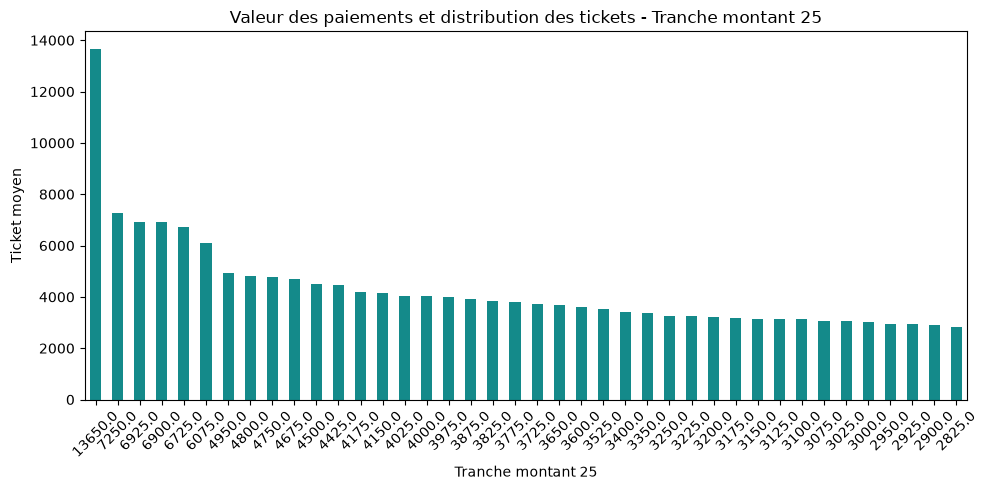

Visuel 2 - Valeur des paiements et distribution des tickets - Type paiement


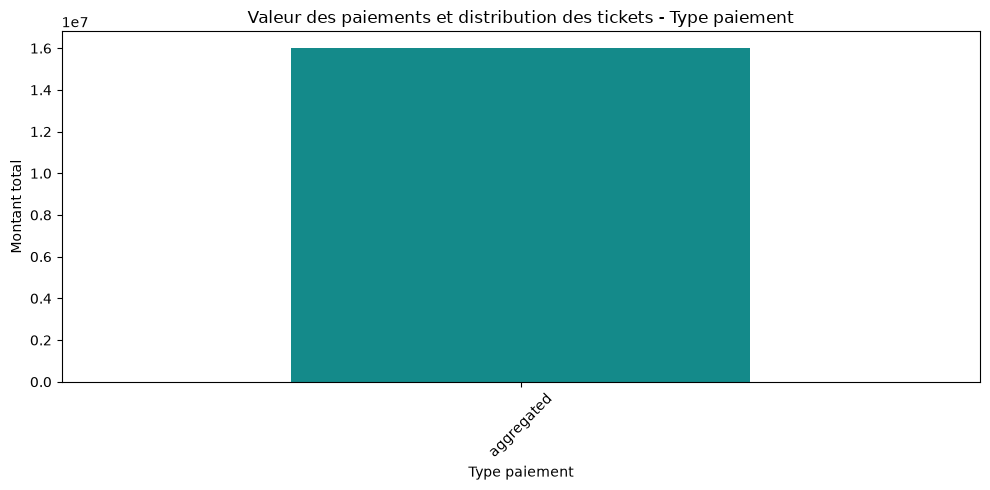

Visuel 3 - Valeur des paiements et distribution des tickets - Échéances


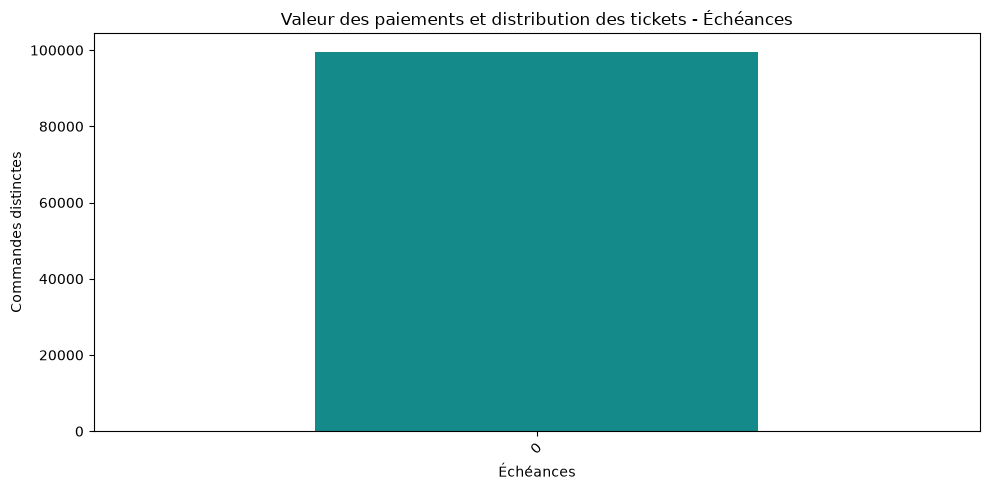

Visuel 4 - Valeur des paiements et distribution des tickets - Mois achat


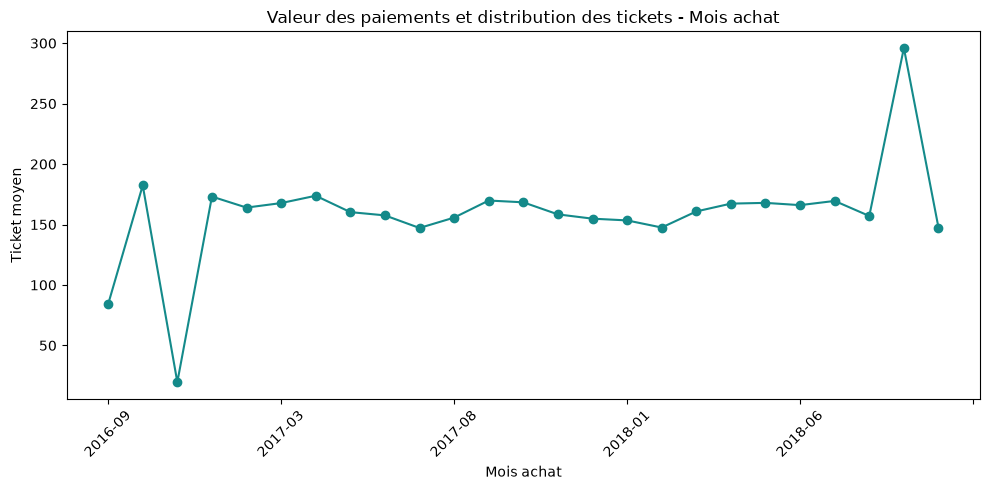

Visuel 5 - Valeur des paiements et distribution des tickets - Année achat


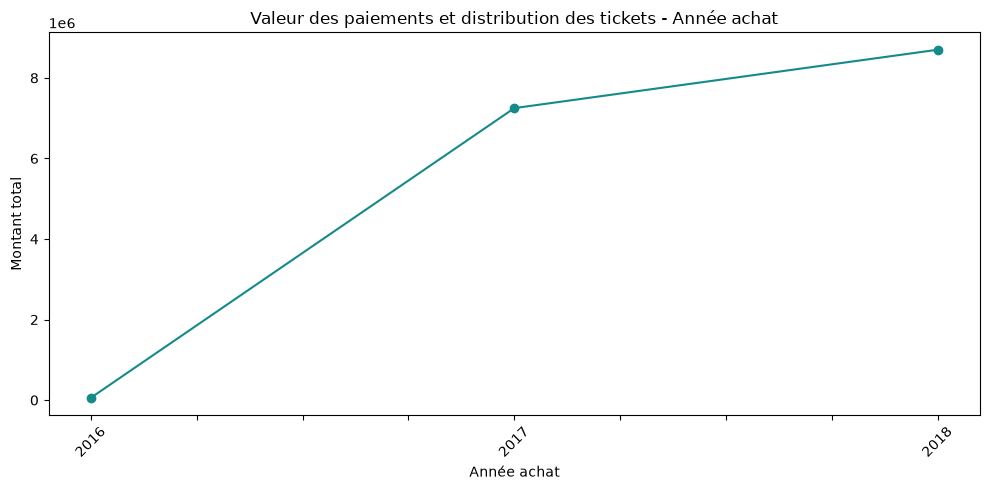

Visuel 6 - Valeur des paiements et distribution des tickets - État client


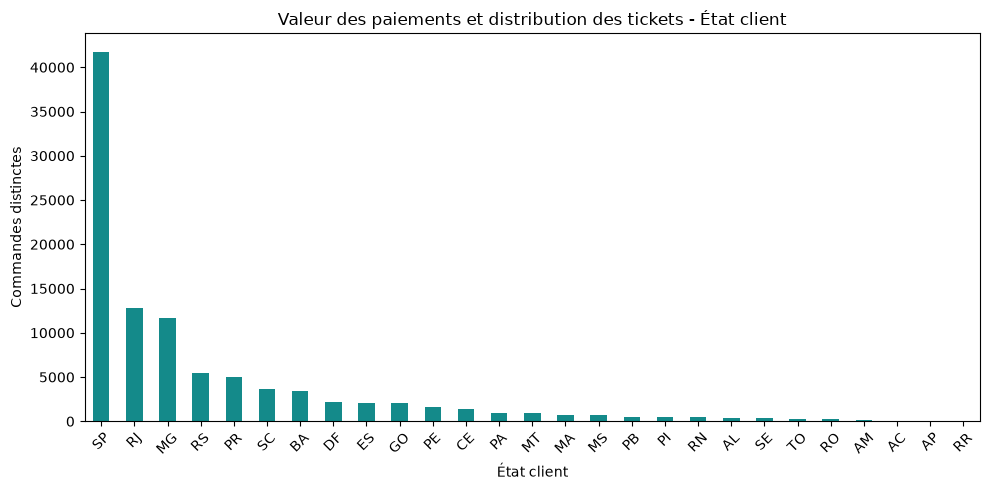

Visuel 7 - Valeur des paiements et distribution des tickets - Ville client


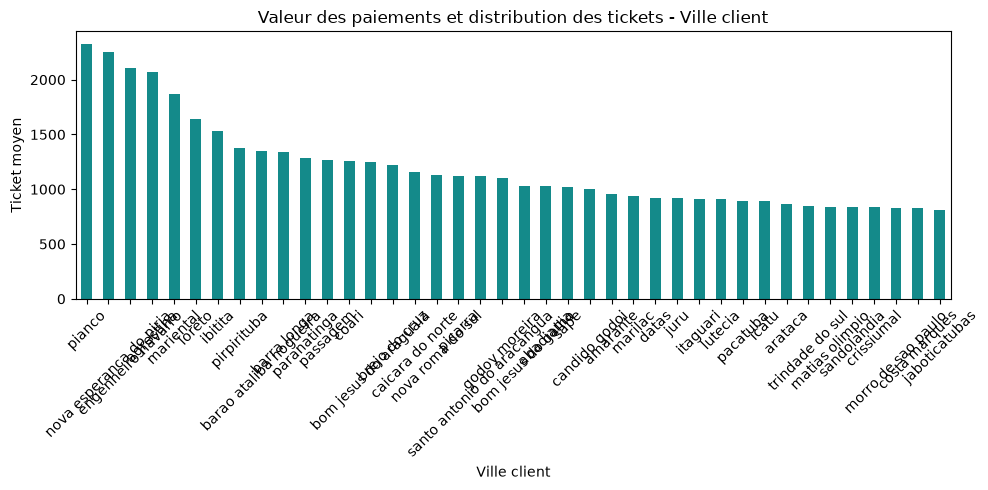

Visuel 8 - Valeur des paiements et distribution des tickets - Type x tranche montant


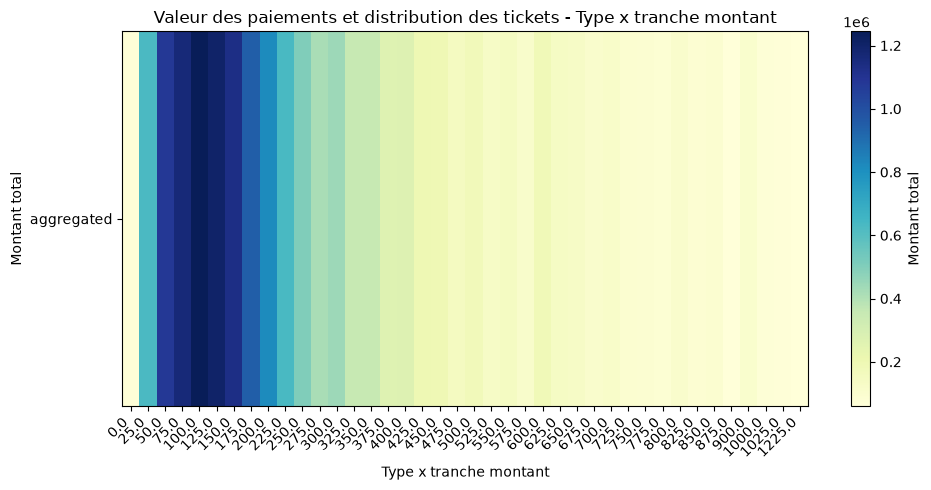

Visuel 9 - Valeur des paiements et distribution des tickets - Échéances x type


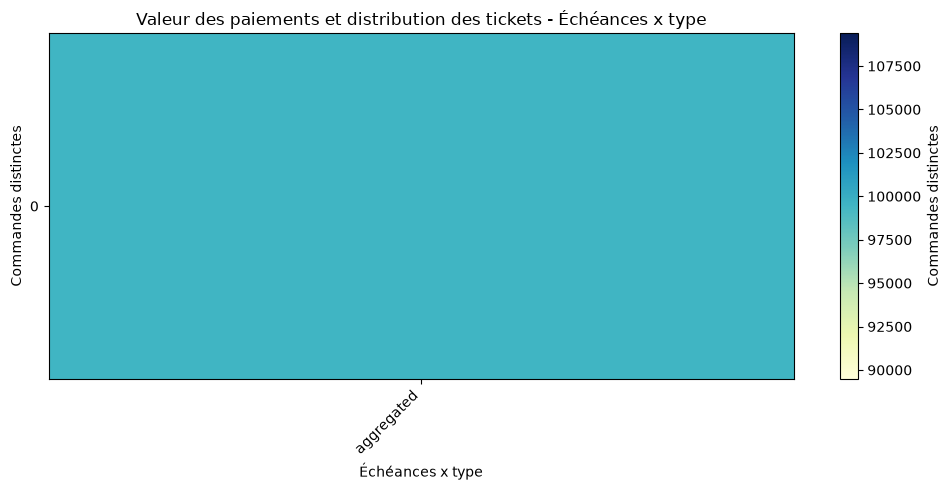

Visuel 10 - Valeur des paiements et distribution des tickets - Commande


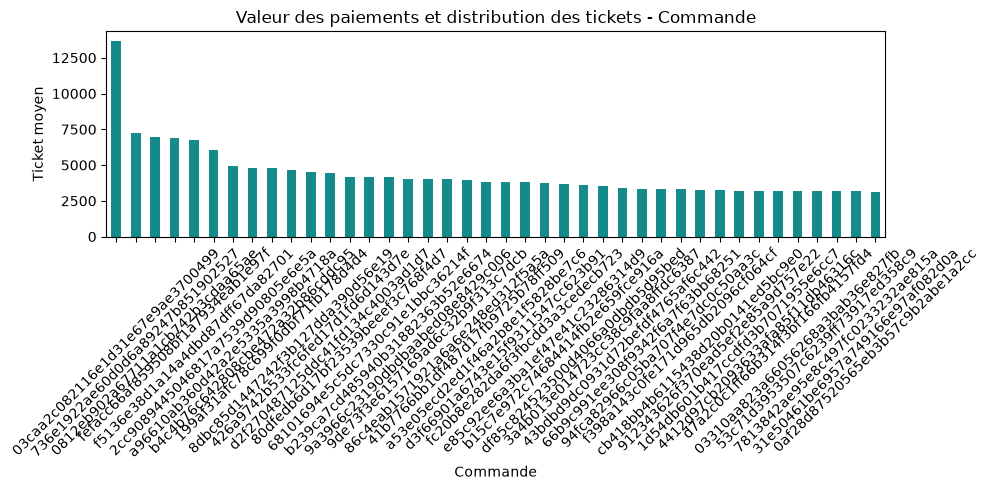

In [5]:
CHARTS=[
  {
    "n": 1,
    "title": "Valeur des paiements et distribution des tickets - Tranche montant 25",
    "dim": {
      "label": "Tranche montant 25",
      "sql": "FLOOR(\"payment_value\"/25)*25",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Valeur des paiements et distribution des tickets - Type paiement",
    "dim": {
      "label": "Type paiement",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Valeur des paiements et distribution des tickets - Échéances",
    "dim": {
      "label": "Échéances",
      "sql": "\"installments\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Valeur des paiements et distribution des tickets - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "line"
  },
  {
    "n": 5,
    "title": "Valeur des paiements et distribution des tickets - Année achat",
    "dim": {
      "label": "Année achat",
      "sql": "\"purchase_date_year\"",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "line"
  },
  {
    "n": 6,
    "title": "Valeur des paiements et distribution des tickets - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Valeur des paiements et distribution des tickets - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Valeur des paiements et distribution des tickets - Type x tranche montant",
    "dim": {
      "label": "Type x tranche montant",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": "FLOOR(\"payment_value\"/25)*25"
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Valeur des paiements et distribution des tickets - Échéances x type",
    "dim": {
      "label": "Échéances x type",
      "sql": "\"installments\"",
      "type": "numeric",
      "series": "\"payment_type\""
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Valeur des paiements et distribution des tickets - Commande",
    "dim": {
      "label": "Commande",
      "sql": "\"order_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 4. Géographie des paiements et comportement client

Comparer les types de paiement et montants selon les attributs géographiques et l’identité analytique du client.

**Drill-down :** État > ville > code postal; client > type de paiement > commande; période en contexte.

Visuel 1 - Géographie des paiements et comportement client - État client


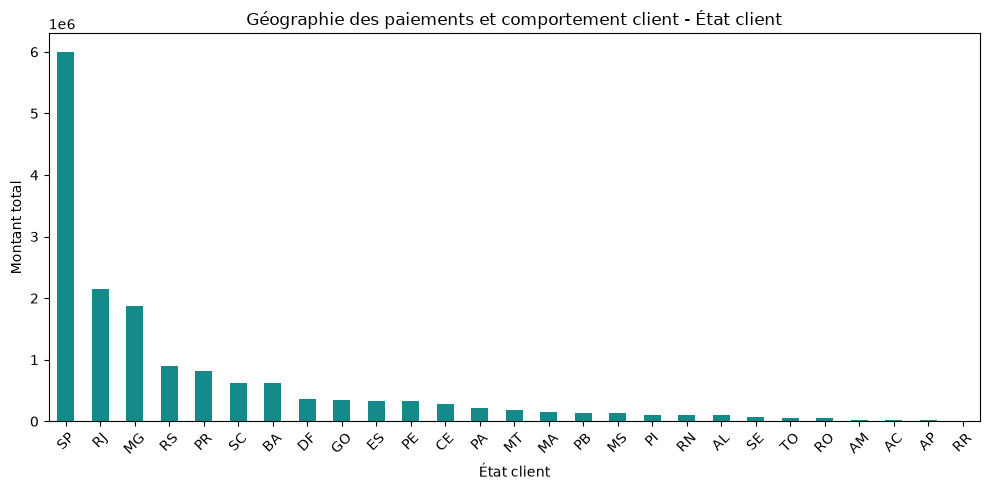

Visuel 2 - Géographie des paiements et comportement client - Ville client


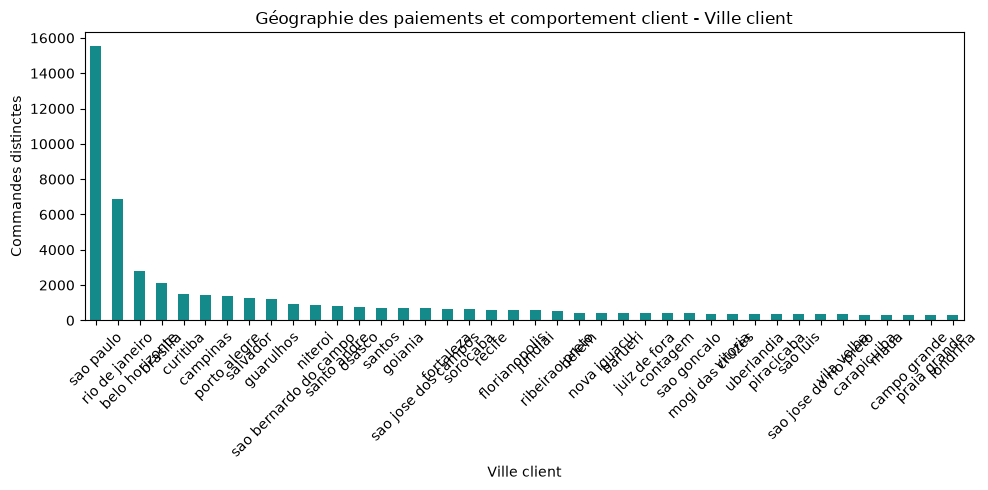

Visuel 3 - Géographie des paiements et comportement client - Code postal


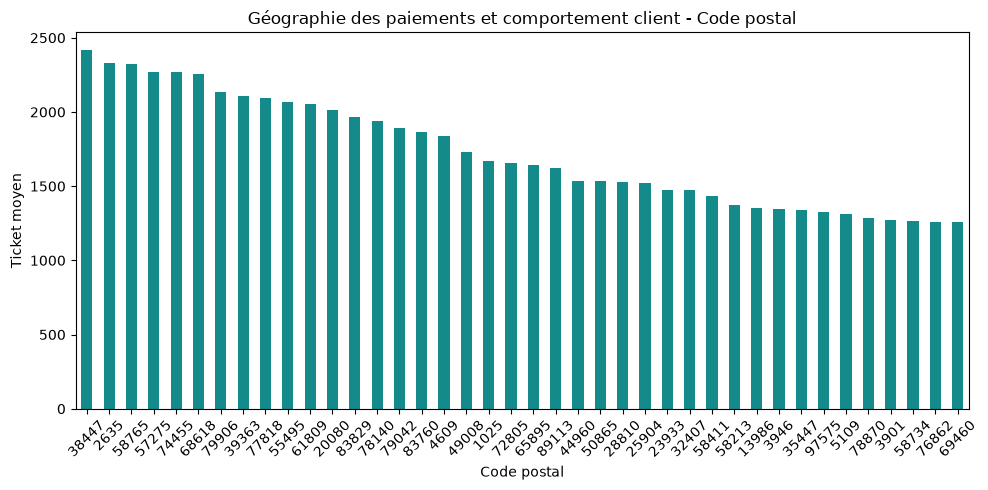

Visuel 4 - Géographie des paiements et comportement client - Client unique


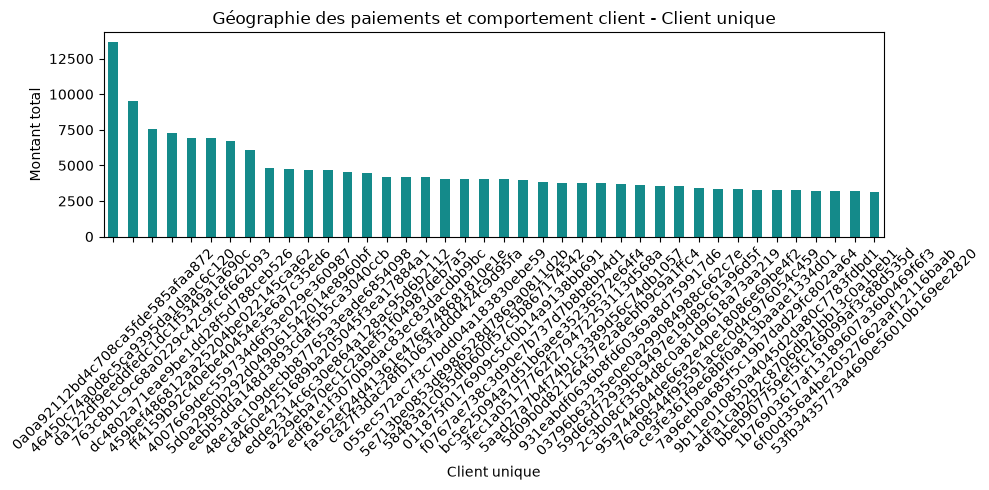

Visuel 5 - Géographie des paiements et comportement client - Type paiement


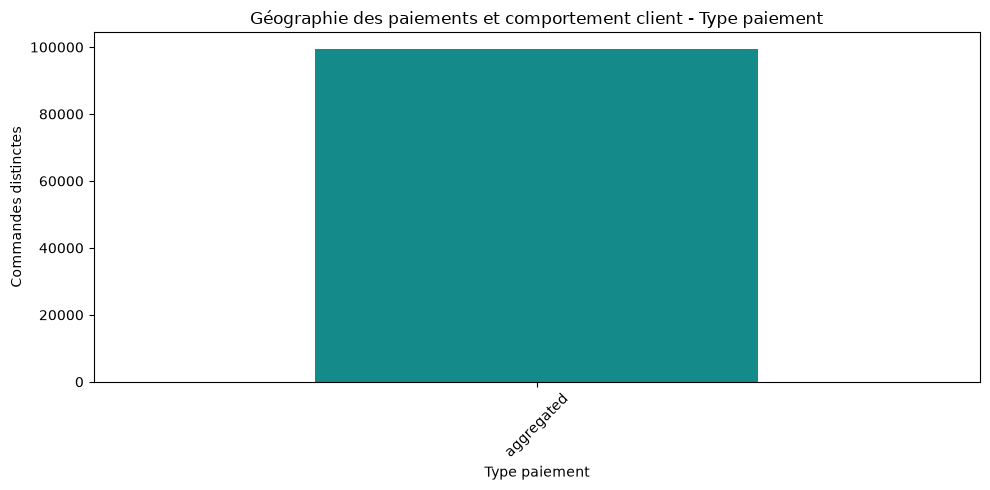

Visuel 6 - Géographie des paiements et comportement client - Mois achat


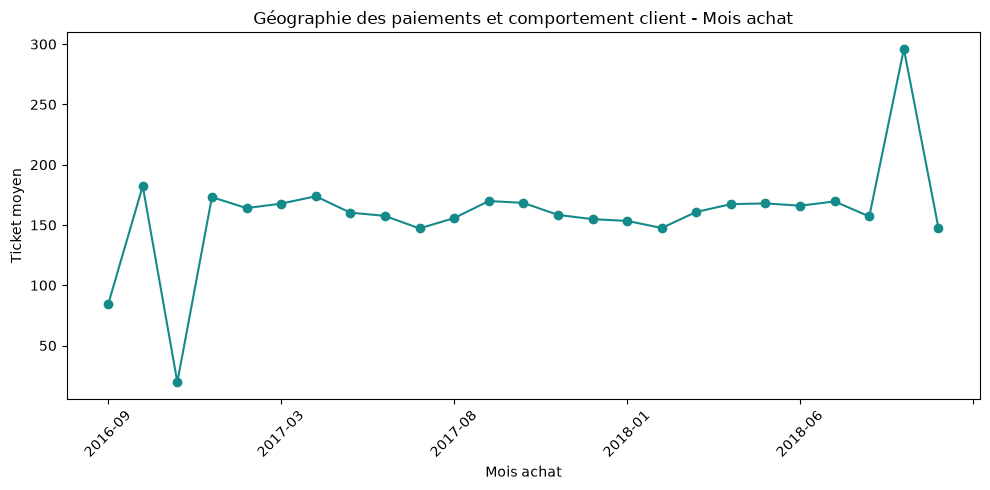

Visuel 7 - Géographie des paiements et comportement client - État x type


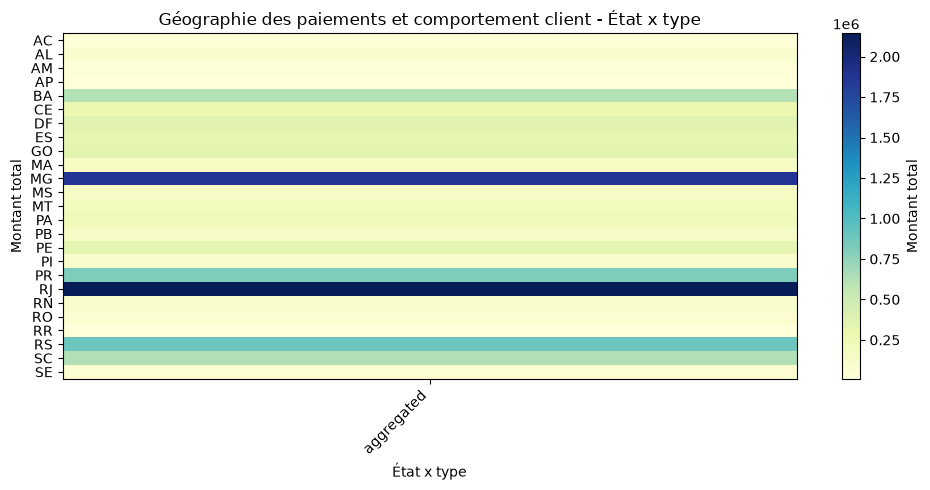

Visuel 8 - Géographie des paiements et comportement client - Ville x type


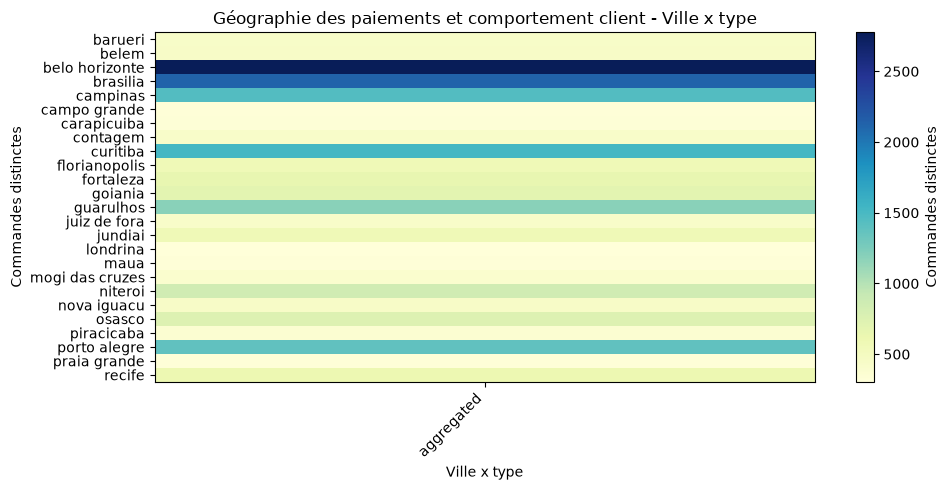

Visuel 9 - Géographie des paiements et comportement client - Client x type


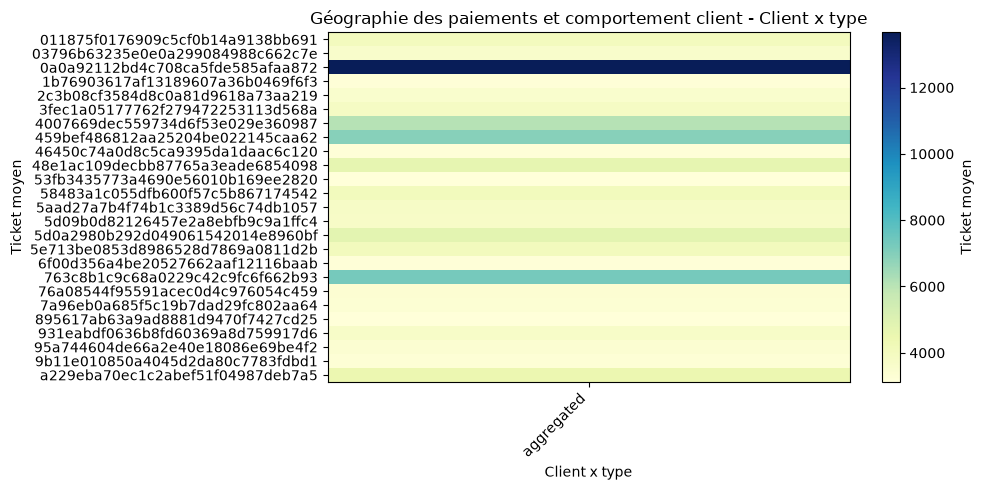

Visuel 10 - Géographie des paiements et comportement client - Heure achat


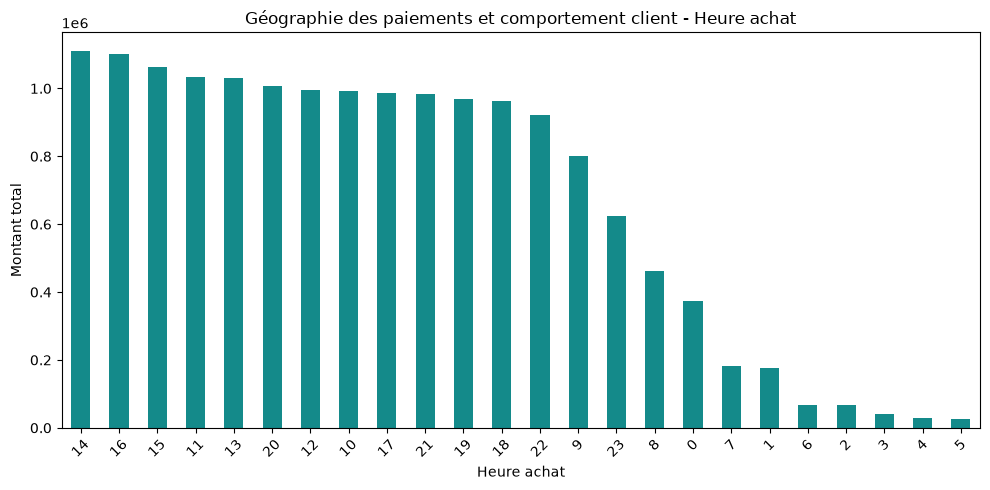

In [6]:
CHARTS=[
  {
    "n": 1,
    "title": "Géographie des paiements et comportement client - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Géographie des paiements et comportement client - Ville client",
    "dim": {
      "label": "Ville client",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 3,
    "title": "Géographie des paiements et comportement client - Code postal",
    "dim": {
      "label": "Code postal",
      "sql": "\"customer_zip_code\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Géographie des paiements et comportement client - Client unique",
    "dim": {
      "label": "Client unique",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Géographie des paiements et comportement client - Type paiement",
    "dim": {
      "label": "Type paiement",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Géographie des paiements et comportement client - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "line"
  },
  {
    "n": 7,
    "title": "Géographie des paiements et comportement client - État x type",
    "dim": {
      "label": "État x type",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": "\"payment_type\""
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 8,
    "title": "Géographie des paiements et comportement client - Ville x type",
    "dim": {
      "label": "Ville x type",
      "sql": "\"customer_city\"",
      "type": "categorical",
      "series": "\"payment_type\""
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Géographie des paiements et comportement client - Client x type",
    "dim": {
      "label": "Client x type",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": "\"payment_type\""
    },
    "metric": {
      "label": "Ticket moyen",
      "sql": "SUM(\"payment_value\") / NULLIF(COUNT(DISTINCT \"order_id\"),0)",
      "pandas": "payment_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Géographie des paiements et comportement client - Heure achat",
    "dim": {
      "label": "Heure achat",
      "sql": "\"purchase_time_hour\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## 5. Couverture des commandes et cohérence des agrégats

Contrôler le nombre de commandes représentées par type de paiement et comparer les montants de paiement par segments. Le rapprochement exact avec les totaux panier relève de fact_order.

**Drill-down :** Type > commande; période > client > état; pour le contrôle panier, ouvrir séparément fact_order et comparer au grain commande.

Visuel 1 - Couverture des commandes et cohérence des agrégats - Type paiement


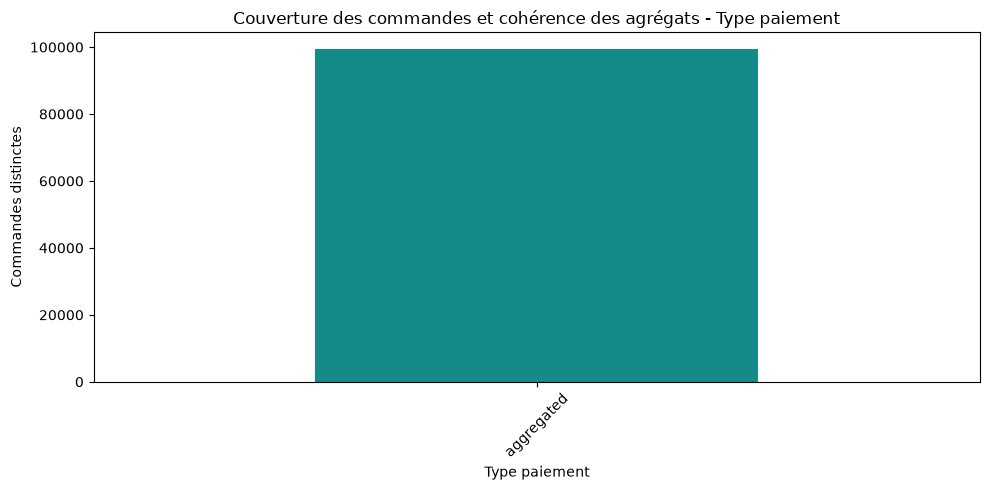

Visuel 2 - Couverture des commandes et cohérence des agrégats - Mois achat


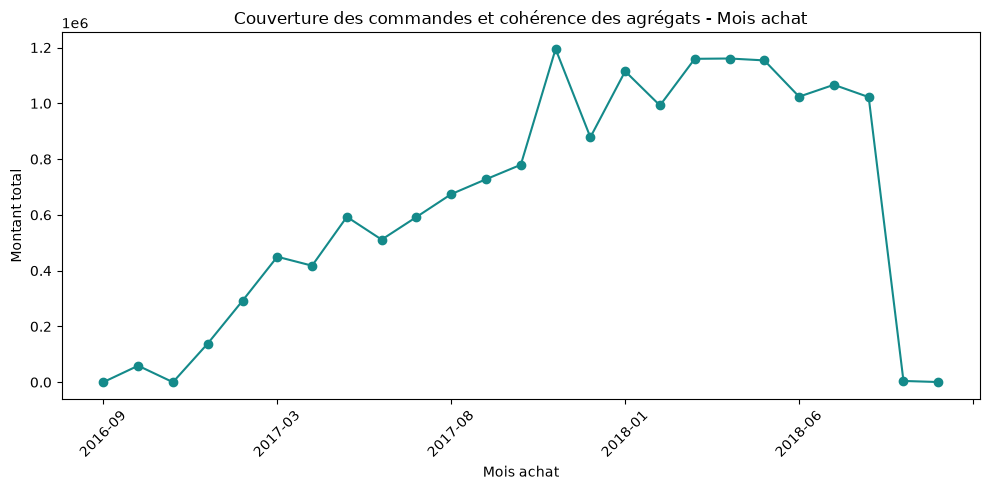

Visuel 3 - Couverture des commandes et cohérence des agrégats - État client


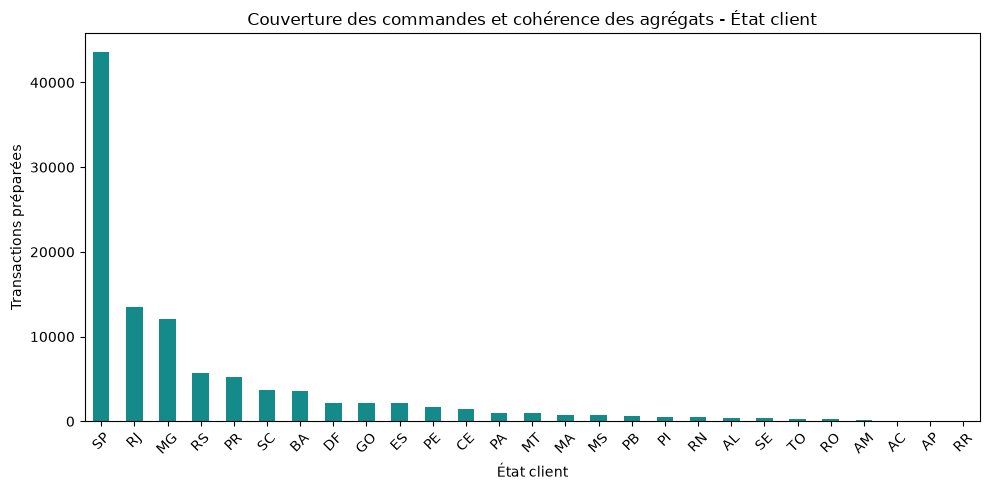

Visuel 4 - Couverture des commandes et cohérence des agrégats - Client unique


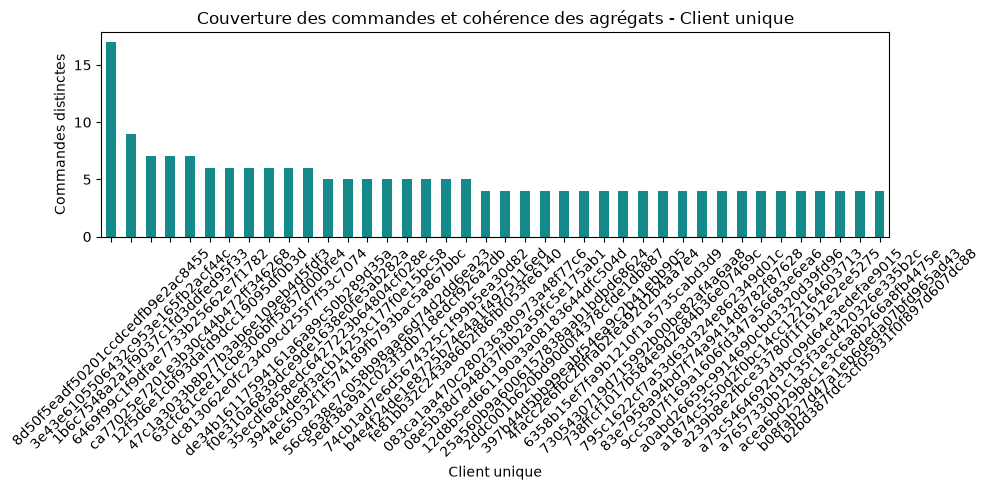

Visuel 5 - Couverture des commandes et cohérence des agrégats - Échéances


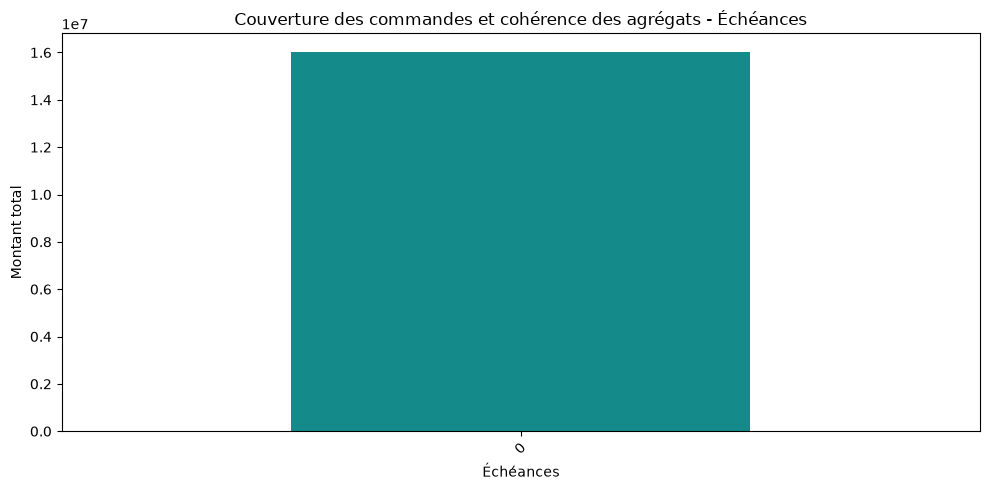

Visuel 6 - Couverture des commandes et cohérence des agrégats - Tranche montant


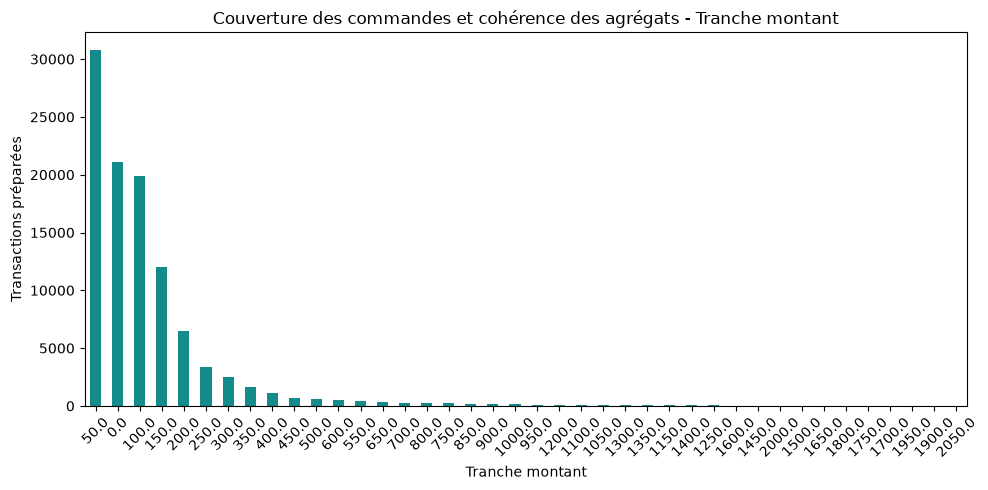

Visuel 7 - Couverture des commandes et cohérence des agrégats - Jour semaine


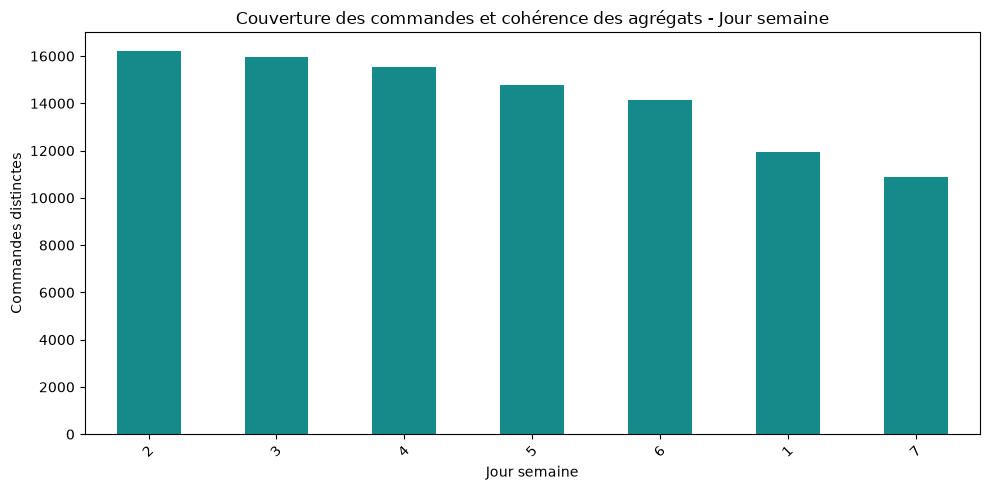

Visuel 8 - Couverture des commandes et cohérence des agrégats - Type x mois


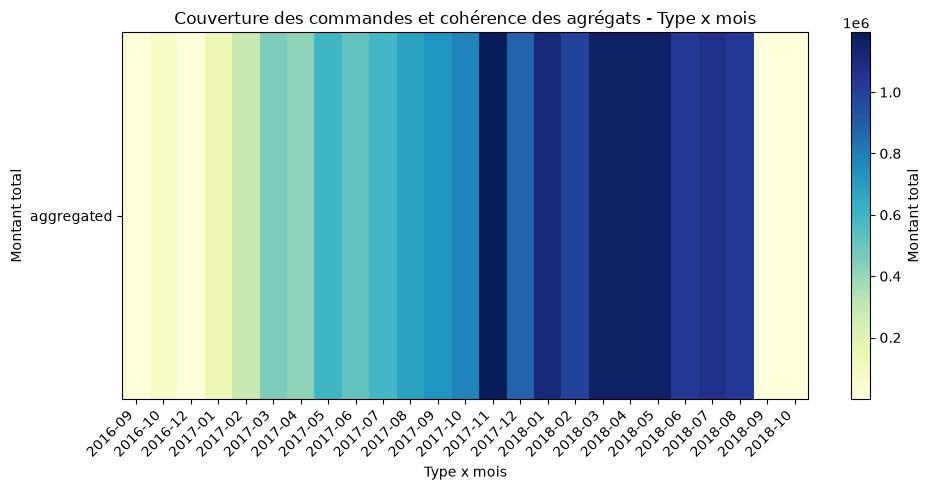

Visuel 9 - Couverture des commandes et cohérence des agrégats - Type x échéances


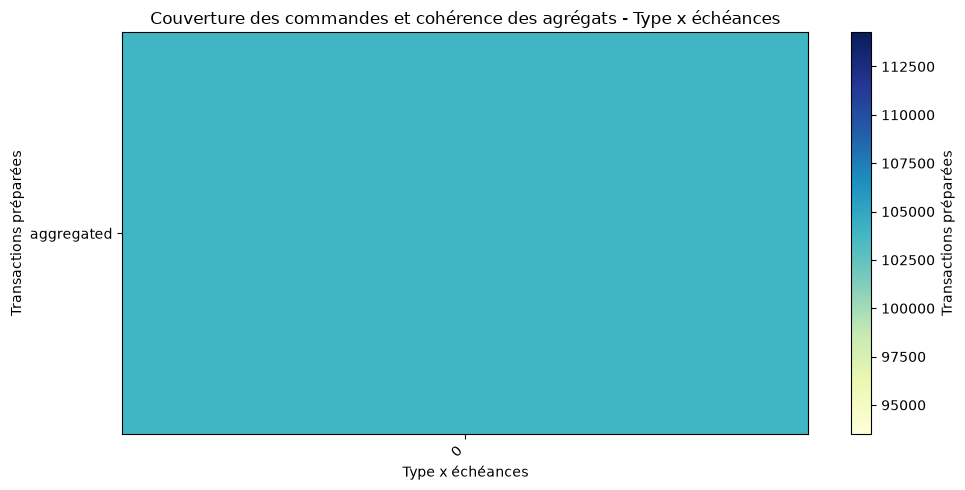

Visuel 10 - Couverture des commandes et cohérence des agrégats - Commande


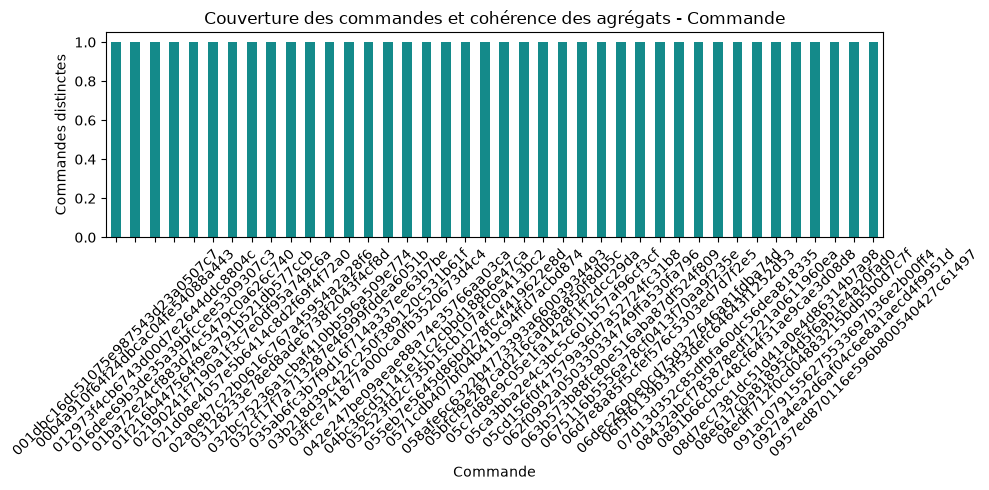

In [7]:
CHARTS=[
  {
    "n": 1,
    "title": "Couverture des commandes et cohérence des agrégats - Type paiement",
    "dim": {
      "label": "Type paiement",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 2,
    "title": "Couverture des commandes et cohérence des agrégats - Mois achat",
    "dim": {
      "label": "Mois achat",
      "sql": "SUBSTRING(\"purchase_date_calendar_date\",1,7)",
      "type": "temporal",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "line"
  },
  {
    "n": 3,
    "title": "Couverture des commandes et cohérence des agrégats - État client",
    "dim": {
      "label": "État client",
      "sql": "\"customer_state\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Transactions préparées",
      "sql": "SUM(\"transaction_count\")",
      "pandas": "transaction_count"
    },
    "kind": "bar"
  },
  {
    "n": 4,
    "title": "Couverture des commandes et cohérence des agrégats - Client unique",
    "dim": {
      "label": "Client unique",
      "sql": "\"customer_unique_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 5,
    "title": "Couverture des commandes et cohérence des agrégats - Échéances",
    "dim": {
      "label": "Échéances",
      "sql": "\"installments\"",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "bar"
  },
  {
    "n": 6,
    "title": "Couverture des commandes et cohérence des agrégats - Tranche montant",
    "dim": {
      "label": "Tranche montant",
      "sql": "FLOOR(\"payment_value\"/50)*50",
      "type": "numeric",
      "series": None
    },
    "metric": {
      "label": "Transactions préparées",
      "sql": "SUM(\"transaction_count\")",
      "pandas": "transaction_count"
    },
    "kind": "bar"
  },
  {
    "n": 7,
    "title": "Couverture des commandes et cohérence des agrégats - Jour semaine",
    "dim": {
      "label": "Jour semaine",
      "sql": "\"purchase_date_weekday\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  },
  {
    "n": 8,
    "title": "Couverture des commandes et cohérence des agrégats - Type x mois",
    "dim": {
      "label": "Type x mois",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": "SUBSTRING(\"purchase_date_calendar_date\",1,7)"
    },
    "metric": {
      "label": "Montant total",
      "sql": "SUM(\"payment_value\")",
      "pandas": "payment_value"
    },
    "kind": "heatmap"
  },
  {
    "n": 9,
    "title": "Couverture des commandes et cohérence des agrégats - Type x échéances",
    "dim": {
      "label": "Type x échéances",
      "sql": "\"payment_type\"",
      "type": "categorical",
      "series": "\"installments\""
    },
    "metric": {
      "label": "Transactions préparées",
      "sql": "SUM(\"transaction_count\")",
      "pandas": "transaction_count"
    },
    "kind": "heatmap"
  },
  {
    "n": 10,
    "title": "Couverture des commandes et cohérence des agrégats - Commande",
    "dim": {
      "label": "Commande",
      "sql": "\"order_id\"",
      "type": "categorical",
      "series": None
    },
    "metric": {
      "label": "Commandes distinctes",
      "sql": "COUNT(DISTINCT \"order_id\")",
      "pandas": "order_id"
    },
    "kind": "bar"
  }
]
for chart in CHARTS:
    print("Visuel",chart["n"],"-",chart["title"])
    run_chart(chart)


## Lecture des résultats\n\nComparer les valeurs aux volumes, vérifier les petits effectifs et suivre les chemins de drill-down du dossier. Les ratios et moyennes se recalculent au niveau affiché. Une association ne démontre pas une causalité.